In [1]:
import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
from scipy.spatial.distance import pdist, squareform

In [2]:
epochs = mne.read_epochs("multi/all-epo.fif", preload=True)
epochs.filter(1.,30)
epochs.apply_baseline(baseline=(1.8, 2))  
epochs = epochs.crop(tmin=2, tmax=8)
#epochs.shift_time(-4, relative=True)
chnames = epochs.ch_names
times = epochs.times - 2
subjects = [1,2,5,7,8,9,10,11,12,13,14,16,18,19,21,22,23,24,25,26]
fs = int(epochs.info["sfreq"])

Reading /home/song-z/Project/multi/all-epo.fif ...
    Found the data of interest:
        t =    -400.00 ...   10000.00 ms
        0 CTF compensation matrices available
Adding metadata with 6 columns
6720 matching events found
No baseline correction applied
0 projection items activated
Setting up band-pass filter from 1 - 30 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 30.00 Hz
- Upper transition bandwidth: 7.50 Hz (-6 dB cutoff frequency: 33.75 Hz)
- Filter length: 825 samples (3.300 s)

Applying baseline correction (mode: mean)


In [3]:
dd_class = []
for sub in subjects:
    epvf = epochs[f'category == "face" and subject == {sub}'].get_data().mean(axis=0)
    epvs = epochs[f'category == "square" and subject == {sub}'].get_data().mean(axis=0)
    epas = epochs[f'category == "speech" and subject == {sub}'].get_data().mean(axis=0)
    epam = epochs[f'category == "music" and subject == {sub}'].get_data().mean(axis=0)
    dd_class.append([epvf, epvs, epas, epam])
dd_class = np.array(dd_class)

In [32]:
percept_class = dd_class[:,:,:,:150].reshape(20, 4, 30, 3, 50).mean(-1).reshape(20, 4, 30*3)
rho_tt, rdmp_all, rdmi_tt, rho_ = [], [], [], []
for sub in range(len(subjects)):
    rdm_p = pdist(percept_class[sub], metric="correlation")
    rho_tt_sub, rdm_i_sub = [], []
    for jj in range(35):
        im = dd_class[sub, :, :, 500 + jj * 25:650 + jj * 25].reshape(4, 30, 3, 50).mean(-1).reshape(4, 30*3)
        rdm_i = pdist(im, metric="correlation")
        rho, p = spearmanr(rdm_p, rdm_i)
        rho_tt_sub.append(rho)
        rdm_i_sub.append(rdm_i)
    rho_sub, p = spearmanr(rdm_p, np.array(rdm_i_sub)[10:].mean(0))
    rdmp_all.append(rdm_p)
    rdmi_tt.append(rdm_i_sub)
    rho_tt.append(rho_tt_sub)
    rho_.append(rho_sub)
rdmp_all = np.array(rdmp_all)
rdmi_tt = np.array(rdmi_tt)
rho_tt = np.array(rho_tt)
rho_ = np.array(rho_)

In [37]:
from scipy.stats import ttest_1samp
tvals, pvals = ttest_1samp(rho_,0,alternative="greater")
rho_.mean(), pvals

(0.44000000000000006, 1.5007095550782795e-05)

In [ ]:
rdmp_mean = squareform(rdmp_all.mean(axis=0))
rdmi_mean = squareform(rdmi_tt[:,10:].mean(axis=1).mean(axis=0))

n_subjects, n_times = rho_tt.shape
nntimes = np.arange(n_times) * 0.1
df_rsa = pd.DataFrame({
    "Subject": np.repeat(np.arange(n_subjects), n_times),
    "Time": np.tile(nntimes, n_subjects),
    "Rho": rho_tt.reshape(-1)
})
"""
from scipy.stats import ttest_1samp
from statsmodels.stats.multitest import multipletests
tvals, pvals = ttest_1samp(rho_tt,0,axis=0,alternative="greater")
reject, pvals_fdr, _, _ = multipletests(pvals,alpha=0.05,method="fdr_bh")
"""

'\nfrom scipy.stats import ttest_1samp\nfrom statsmodels.stats.multitest import multipletests\ntvals, pvals = ttest_1samp(rho_tt,0,axis=0,alternative="greater")\nreject, pvals_fdr, _, _ = multipletests(pvals,alpha=0.05,method="fdr_bh")\n'

/tmp/ipykernel_722386/2142869813.py:21: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


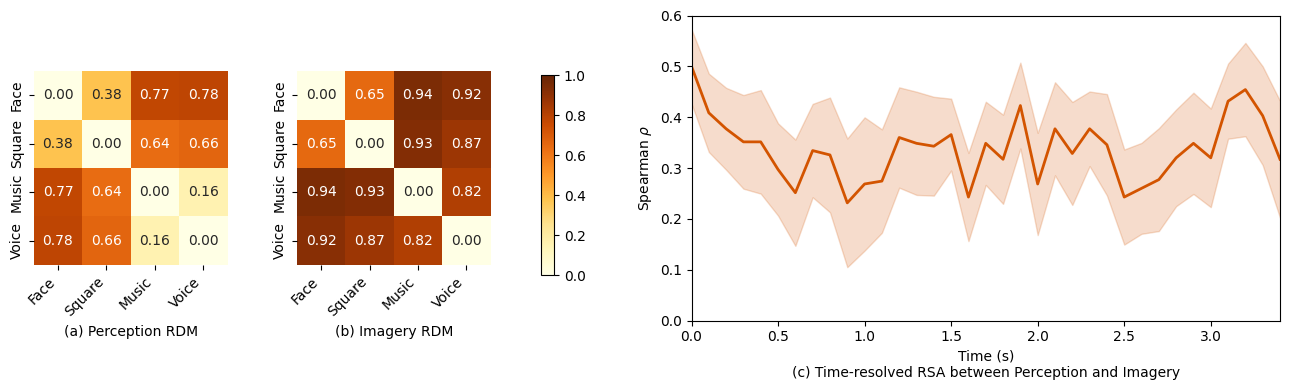

In [23]:
fig = plt.figure(figsize=(13, 4))
ax_p = plt.subplot2grid((1, 10), (0, 0), colspan=2)
ax_i = plt.subplot2grid((1, 10), (0, 2), colspan=2)
ax_t = plt.subplot2grid((1, 10), (0, 5), colspan=5)
bar1 = fig.add_axes([0.42, 0.3, 0.01, 0.5])

labels = ['Face', 'Square', 'Music', 'Voice']
hmp = sns.heatmap(rdmp_mean,annot=True,fmt='.2f',cmap='YlOrBr',vmin=0,vmax=1,xticklabels=labels,yticklabels=labels,ax=ax_p,cbar=False,square=True)
hmi = sns.heatmap(rdmi_mean,annot=True,fmt='.2f',cmap='YlOrBr',vmin=0,vmax=1,xticklabels=labels,yticklabels=labels,ax=ax_i,cbar=False,square=True)
ax_p.set_xlabel('(a) Perception RDM')
ax_i.set_xlabel('(b) Imagery RDM')
ax_p.set_xticklabels(labels, rotation=45, ha="right")
ax_i.set_xticklabels(labels, rotation=45, ha="right")
fig.colorbar(hmp.collections[0],cax=bar1)
sns.lineplot(data=df_rsa,x="Time",y="Rho",errorbar="se",linewidth=2,ax=ax_t,color="#D35400")
ax_t.set_xlabel('Time (s)\n(c) Time-resolved RSA between Perception and Imagery')
ax_t.set_ylabel(r'Spearman $\rho$')
ax_t.set_xlim(0, 3.4)
ax_t.set_ylim(0, 0.6)

plt.tight_layout()
plt.savefig("multi/fig/rdm.pdf", bbox_inches="tight")
plt.show()
